# Modelo continuo de competencia con migración

Ampliamos el modelo de competencia con carga ambiental para representar dos
hábitats. Cada hábitat contiene presas $P$ y dos depredadores, $D$ y $C$,
que compiten por las mismas presas. Las tres poblaciones pueden migrar entre
hábitats; sus tasas de migración pueden ser distintas.

El cuaderno sigue el mismo orden que los otros modelos: **parámetros, sistema
de ecuaciones, simulación, evolución temporal y diagramas de fase**. Se
comparan los resultados con migración y con los hábitats aislados. Los
parámetros de ejemplo son ilustrativos, no un ajuste a datos.

Las poblaciones son abundancias continuas. La migración conecta los dos
hábitats y, por sí sola, conserva el total de cada especie. Ejecutar las
celdas en orden.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

# Parámetros por hábitat: los arreglos siguen el orden [A, B].
nu = np.array([1.0, 0.8])          # Crecimiento de las presas
mu = np.array([0.02, 0.02])       # Depredación de D sobre P
kappa = np.array([0.018, 0.016])  # Depredación de C sobre P
iota = np.array([0.001, 0.0015]) # Carga ambiental de las presas
delta = np.array([0.4, 0.32])     # Mortalidad de D
alpha = np.array([0.01, 0.012])   # Reproducción de D por las presas
Delta = np.array([0.36, 0.42])    # Mortalidad de C
beta = np.array([0.01, 0.008])    # Reproducción de C por las presas

h_D = np.array([0.004, 0.003])    # Saturación de D; cero recupera la respuesta original
h_C = np.array([0.005, 0.004])    # Saturación de C
s_D = np.array([0.002, 0.002])    # Autorregulación de D
s_C = np.array([0.002, 0.002])    # Autorregulación de C
eta_DC = np.array([0.0005, 0.0005])  # Competencia de C sobre D
eta_CD = np.array([0.0005, 0.0005])  # Competencia de D sobre C

# Migración por día: filas [A -> B, B -> A]; columnas [P, D, C].
migracion = np.array([
    [0.030, 0.015, 0.008],
    [0.015, 0.008, 0.020],
])

# Abundancias iniciales por hábitat. C empieza ausente en B.
P0 = np.array([120.0, 90.0])
D0 = np.array([10.0, 4.0])
C0 = np.array([10.0, 0.0])

dias = 365
puntos = 2000


## Sistema de ecuaciones

En cada hábitat, el crecimiento de las presas tiene carga ambiental. La
depredación se satura conforme aumenta $P$. Los depredadores también pueden
competir directamente y regular su propio crecimiento:

$$f_{P,i}=P_i\left(\nu_i-\iota_iP_i-
\frac{\mu_iD_i}{1+h_{D,i}P_i}-
\frac{\kappa_iC_i}{1+h_{C,i}P_i}\right),$$

$$f_{D,i}=D_i\left(\frac{\alpha_iP_i}{1+h_{D,i}P_i}-
\delta_i-s_{D,i}D_i-\eta_{DC,i}C_i\right),$$

$$f_{C,i}=C_i\left(\frac{\beta_iP_i}{1+h_{C,i}P_i}-
\Delta_i-s_{C,i}C_i-\eta_{CD,i}D_i\right).$$

Para cada especie $X\in\{P,D,C\}$, su flujo neto de A a B es
$J_X=m_{AB,X}X_A-m_{BA,X}X_B$. Por ello,
$dX_A/dt=f_{X,A}-J_X$ y $dX_B/dt=f_{X,B}+J_X$. Al sumar los dos hábitats,
la migración desaparece del balance: el transporte cambia la distribución,
mientras que la reproducción, la mortalidad y la depredación cambian el total.

In [2]:
def DP(t, y, nu, mu, kappa, iota, delta, alpha, Delta, beta,
       h_D, h_C, s_D, s_C, eta_DC, eta_CD, migracion):
    # Cada fila de y contiene [P, D, C] en un hábitat: primero A, después B.
    poblaciones = y.reshape(2, 3)
    P, D, C = poblaciones.T

    # Dinámica local en cada hábitat.
    den_D = 1 + h_D * P
    den_C = 1 + h_C * P
    dP = P * (nu - iota * P - mu * D / den_D - kappa * C / den_C)
    dD = D * (alpha * P / den_D - delta - s_D * D - eta_DC * C)
    dC = C * (beta * P / den_C - Delta - s_C * C - eta_CD * D)
    derivada = np.column_stack((dP, dD, dC))

    # Flujo neto para cada especie: sale de A y entra en B.
    flujo = migracion[0] * poblaciones[0] - migracion[1] * poblaciones[1]
    derivada[0] -= flujo
    derivada[1] += flujo
    return derivada.ravel()


## Simulación

Usamos `solve_ivp` para integrar las seis ecuaciones en el tiempo. El método
RK45 ajusta los pasos internos y guarda la solución en `puntos` tiempos
uniformes. En cada escenario se devuelve el tiempo, las poblaciones y el
número de evaluaciones del modelo. La forma de la matriz de poblaciones es
`(tiempo, hábitat, especie)`.

In [3]:
def simu_DP(P0, D0, C0, dias, puntos, migracion):
    y0 = np.column_stack((P0, D0, C0)).ravel()
    tiempo = np.linspace(0, dias, puntos)

    sol = solve_ivp(
        DP,
        (0, dias),
        y0,
        args=(nu, mu, kappa, iota, delta, alpha, Delta, beta,
              h_D, h_C, s_D, s_C, eta_DC, eta_CD, migracion),
        t_eval=tiempo,
        method="RK45",
        rtol=1e-8,
        atol=1e-10,
        max_step=0.5,
    )

    if not sol.success:
        raise RuntimeError(sol.message)
    if not np.isfinite(sol.y).all() or np.any(sol.y < -1e-7):
        raise RuntimeError("La integración produjo poblaciones inválidas; revise los parámetros.")

    poblaciones = sol.y.T.reshape(puntos, 2, 3)
    return sol.t, poblaciones, sol.nfev


# Comparamos los mismos parámetros y condiciones iniciales con ambas opciones.
tiempo, poblaciones, evaluaciones = simu_DP(P0, D0, C0, dias, puntos, migracion)
tiempo_sin, poblaciones_sin, evaluaciones_sin = simu_DP(
    P0, D0, C0, dias, puntos, np.zeros_like(migracion)
)

flujo_neto = (migracion[0] * poblaciones[:, 0, :]
              - migracion[1] * poblaciones[:, 1, :])
print(f"Evaluaciones del modelo: {evaluaciones} con migración, "
      f"{evaluaciones_sin} sin migración.")


Evaluaciones del modelo: 16298 con migración, 19028 sin migración.


## Evolución temporal y flujos de migración

Las gráficas comparan las abundancias de cada especie en ambos hábitats.
La línea continua representa la migración; la línea discontinua, los
hábitats aislados. El flujo positivo indica movimiento neto de A a B; el
negativo indica movimiento neto de B a A.

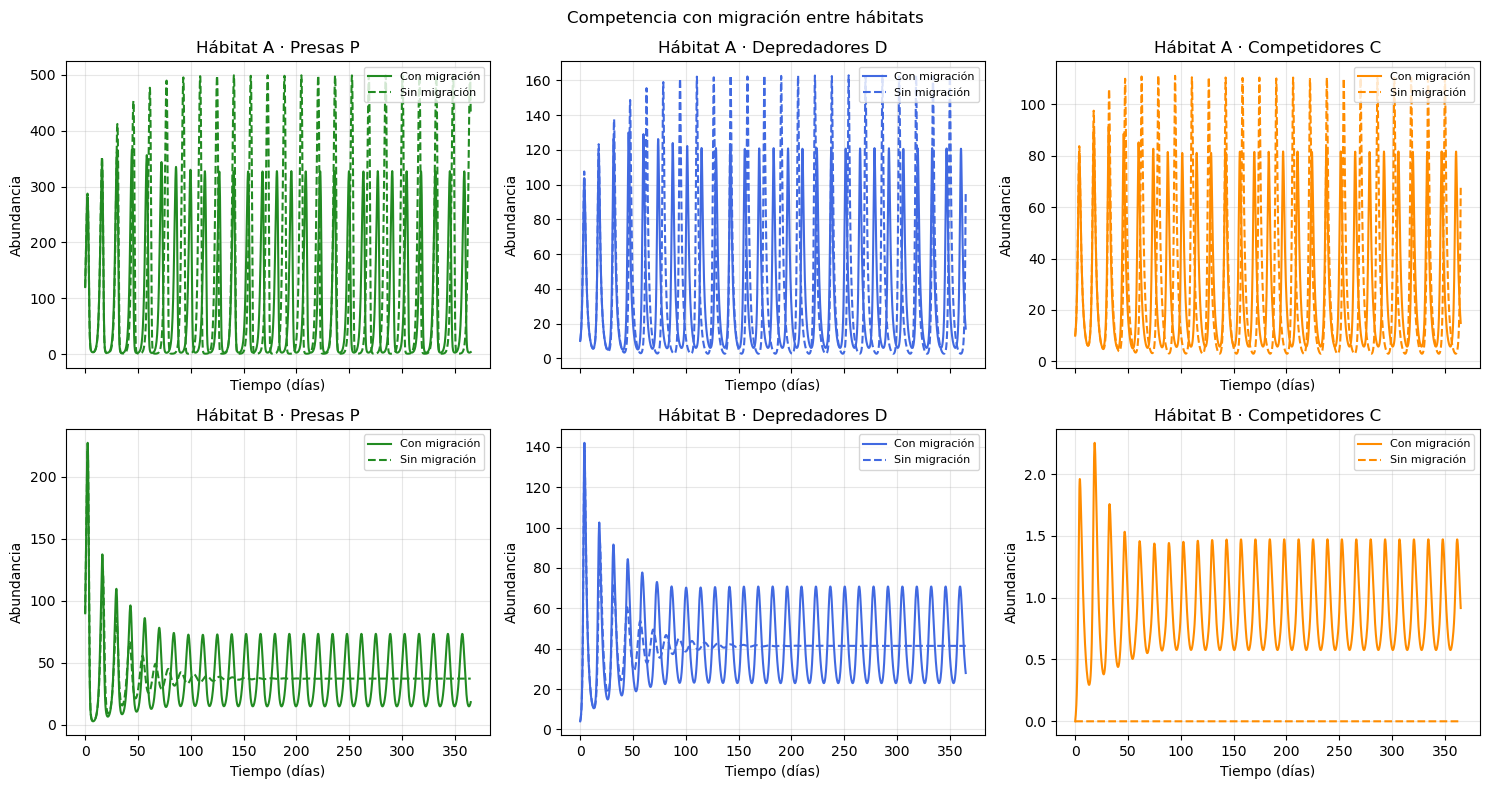

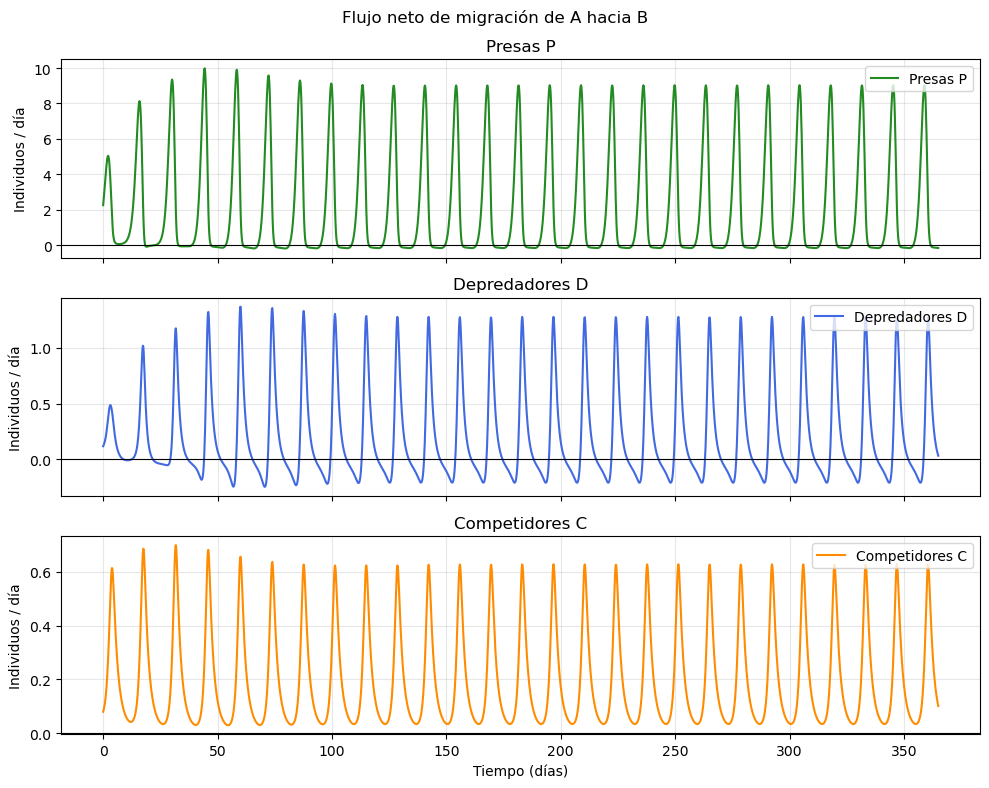

In [4]:
especies = ("Presas P", "Depredadores D", "Competidores C")
colores = ("forestgreen", "royalblue", "darkorange")
habitats = ("Hábitat A", "Hábitat B")

fig, ejes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for s, ax in enumerate(ejes.flat):
    h = s // 3
    especie = s % 3
    ax.plot(tiempo, poblaciones[:, h, especie], color=colores[especie],
            label="Con migración")
    ax.plot(tiempo_sin, poblaciones_sin[:, h, especie], color=colores[especie],
            linestyle="--", label="Sin migración")
    ax.set_title(f"{habitats[h]} · {especies[especie]}")
    ax.set_xlabel("Tiempo (días)")
    ax.set_ylabel("Abundancia")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Competencia con migración entre hábitats")
fig.tight_layout()
plt.show()

fig, ejes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for s, ax in enumerate(ejes):
    ax.plot(tiempo, flujo_neto[:, s], color=colores[s], label=especies[s])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("Individuos / día")
    ax.set_title(especies[s])
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
ejes[-1].set_xlabel("Tiempo (días)")
fig.suptitle("Flujo neto de migración de A hacia B")
fig.tight_layout()
plt.show()


## Diagramas de fase

El plano de fase muestra a los dos depredadores en cada hábitat. Comparar
las trayectorias con migración y sin migración ayuda a observar cómo cambia
la competencia entre ellos.

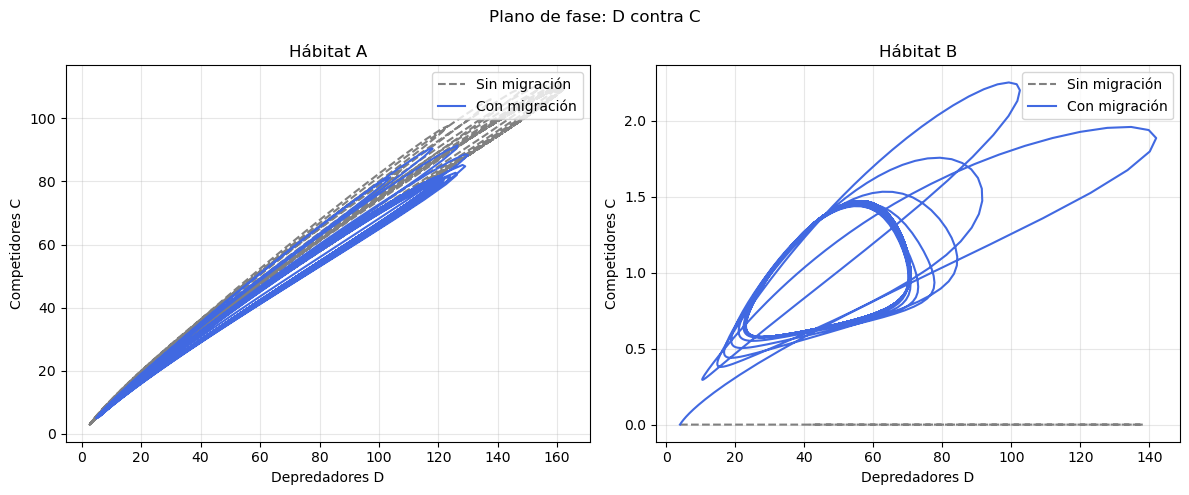

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for h, ax in enumerate(ejes):
    ax.plot(poblaciones_sin[:, h, 1], poblaciones_sin[:, h, 2],
            "--", color="gray", label="Sin migración")
    ax.plot(poblaciones[:, h, 1], poblaciones[:, h, 2],
            color="royalblue", label="Con migración")
    ax.set_title(habitats[h])
    ax.set_xlabel("Depredadores D")
    ax.set_ylabel("Competidores C")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
fig.suptitle("Plano de fase: D contra C")
fig.tight_layout()
plt.show()
